# Final model evaluation on the untouched test set

This notebook loads the frozen feature list and the final models saved by `model_development.ipynb` for the split named by `SPLIT_SCHEME`, and evaluates both training runs in one pass:

- `full`: the `L`, `H`, and `All` models tuned on the full training and validation sets and refit on both;
- `balanced`: the models tuned and refit on the balanced Low+High training and validation subsets (Low-MP compounds undersampled to the High-MP count in each partition).

Models are not retrained here, and no hyperparameter optimization or feature selection is performed. Every model predicts the complete test set; metrics are reported overall and separately for Low- and High-MP compounds. Predictions, metrics and the configuration are written to `outputs/<SPLIT_SCHEME>/<run>/`.

Figures are only displayed: each figure cell has a commented `fig.savefig(...)` line, and uncommenting it saves that figure to the run's output folder. Each run has its own labels and colours (`RUN_STYLES`).

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    raise FileNotFoundError('Run this notebook from the repository root or a project subdirectory.')

SPLIT_SCHEME = 'stereo_cleaned'  # folder written by 1_data_split/data_split.ipynb
RUNS = ['full', 'balanced']  # training variants of model_development.ipynb
MODEL_TYPES = ['LGB']
DATA_TYPES = ['L', 'H', 'All']
FEATURE_ROOT = PROJECT_ROOT / '2_feature_engineering' / 'outputs' / SPLIT_SCHEME
FEATURE_LIST_PATH = FEATURE_ROOT / 'selected_features.csv'
TEST_PATH = FEATURE_ROOT / 'selected_features' / 'test_selected_features.parquet'
MODEL_ROOT = PROJECT_ROOT / '3_model_development' / 'models' / SPLIT_SCHEME
OUTPUT_ROOT = PROJECT_ROOT / '4_model_evaluation' / 'outputs' / SPLIT_SCHEME
for run in RUNS:
    (OUTPUT_ROOT / run / 'predictions').mkdir(parents=True, exist_ok=True)

MP_COLUMN = 'MP'
CLASS_COLUMN = 'MP_class'
FINAL_FIT_MODE = 'train_plus_validation'

# Figure labels and colours per run, keyed by regime. They name both the models (x-axis)
# and the test subsets the models are evaluated on (bar colours).
RUN_STYLES = {
    'full': {
        'labels': {'L': 'Low-MP', 'H': 'High-MP', 'All': 'All-MP'},
        'colors': {'L': '#477C9B', 'H': '#CA806B', 'All': '#83A891'},
    },
    'balanced': {
        'labels': {'L': 'Low-MP (US)', 'H': 'High-MP', 'All': 'BAL-MP'},
        'colors': {'L': '#7776B3', 'H': '#CA806B', 'All': '#83A891'},
    },
}
SUBSET_REGIME = {'low': 'L', 'high': 'H', 'all': 'All'}

print('Split scheme:', SPLIT_SCHEME)
print('Runs:', RUNS)
print('Test input:', TEST_PATH.relative_to(PROJECT_ROOT))
print('Model directory:', MODEL_ROOT.relative_to(PROJECT_ROOT))
print('Evaluation output directory:', OUTPUT_ROOT.relative_to(PROJECT_ROOT))

Split scheme: stereo_cleaned
Runs: ['full', 'balanced']
Test input: 2_feature_engineering/outputs/stereo_cleaned/selected_features/test_selected_features.parquet
Model directory: 3_model_development/models/stereo_cleaned
Evaluation output directory: 4_model_evaluation/outputs/stereo_cleaned


## Load the frozen test table and feature list

The test table is loaded only in this final evaluation notebook. The explicit feature list prevents metadata from entering the predictor matrix.

In [2]:
if not FEATURE_LIST_PATH.is_file():
    raise FileNotFoundError(f'Missing selected feature list: {FEATURE_LIST_PATH}')

feature_names = pd.read_csv(FEATURE_LIST_PATH)['Feature'].dropna().astype(str).tolist()
test_data = pd.read_parquet(TEST_PATH)

missing_features = sorted(set(feature_names).difference(test_data.columns))
missing_columns = sorted({MP_COLUMN, CLASS_COLUMN}.difference(test_data.columns))
if missing_features or missing_columns:
    raise ValueError(f'test: missing features={missing_features[:5]}, metadata={missing_columns}')
if test_data[feature_names].isna().any().any():
    raise ValueError('test contains NaN values in the selected features.')

print('Test:', test_data.shape)
print('Selected feature count:', len(feature_names))

Test: (55427, 1711)
Selected feature count: 1690


## Define model and regime helpers

The regime helper accepts both the current `low`/`high` labels and the shorthand `L`/`H` labels. Each saved model's metadata must match this notebook's split scheme, its run (training variant), and the feature count.

In [3]:
def normalized_class(frame):
    labels = frame[CLASS_COLUMN].astype(str).str.strip().str.lower()
    return labels.replace({'l': 'low', 'h': 'high'})

def load_final_model(run, model_type, regime):
    stem = f'{model_type}_{regime}_{FINAL_FIT_MODE}'
    model_path = MODEL_ROOT / run / f'best_model_{stem}.joblib'
    metadata_path = MODEL_ROOT / run / f'model_metadata_{stem}.json'
    for path in [model_path, metadata_path]:
        if not path.is_file():
            raise FileNotFoundError(f'Missing saved final model file: {path}')
    metadata = json.loads(metadata_path.read_text())
    expected = {'split_scheme': SPLIT_SCHEME, 'training_variant': run,
                'selected_feature_count': len(feature_names), 'test_used': False}
    mismatched = {key: metadata.get(key) for key, value in expected.items() if metadata.get(key) != value}
    if mismatched:
        raise ValueError(f'{run}/{model_path.name} metadata does not match this evaluation: {mismatched}')
    return joblib.load(model_path)

def calculate_metrics(y_true, y_pred):
    return {
        'N_compounds': int(len(y_true)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'R2': float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
    }

## Evaluate both runs on the complete test set

The saved final models are used without modification. Each model predicts the entire unchanged test table; metrics are then calculated overall and separately for the Low- and High-MP test subsets.

In [4]:
test_labels = normalized_class(test_data)
subset_masks = {
    'low': test_labels == 'low',
    'high': test_labels == 'high',
    'all': pd.Series(True, index=test_data.index),
}
prediction_columns = [column for column in ['SMILES', MP_COLUMN, CLASS_COLUMN, 'Source'] if column in test_data.columns]

metrics_tables, predictions_by_run = {}, {}
for run in RUNS:
    output_dir = OUTPUT_ROOT / run
    prediction_tables, metric_rows = [], []
    for model_type in MODEL_TYPES:
        for regime in DATA_TYPES:
            predictions = load_final_model(run, model_type, regime).predict(test_data[feature_names])
            prediction_table = test_data[prediction_columns].copy()
            prediction_table['MP_pred'] = predictions
            prediction_table['Model_type'] = model_type
            prediction_table['Training_regime'] = regime
            prediction_table.to_parquet(output_dir / 'predictions' / f'predictions_{model_type}_{regime}.parquet', index=False)
            prediction_tables.append(prediction_table)
            for evaluation_subset, subset_mask in subset_masks.items():
                metrics = calculate_metrics(test_data.loc[subset_mask, MP_COLUMN], predictions[subset_mask.to_numpy()])
                metric_rows.append({'Model_type': model_type, 'Training_regime': regime,
                                    'Evaluation_subset': evaluation_subset, **metrics})

    predictions_by_run[run] = pd.concat(prediction_tables, ignore_index=True)
    predictions_by_run[run].to_parquet(output_dir / 'all_test_predictions.parquet', index=False)
    metrics_tables[run] = pd.DataFrame(metric_rows)
    metrics_tables[run].to_csv(output_dir / 'evaluation_metrics.csv', index=False)
    config = {
        'split_scheme': SPLIT_SCHEME,
        'training_variant': run,
        'model_types': MODEL_TYPES,
        'training_regimes': DATA_TYPES,
        'final_fit_mode': FINAL_FIT_MODE,
        'test_used_for': 'final_evaluation_only',
        'feature_list': str(FEATURE_LIST_PATH.relative_to(PROJECT_ROOT)),
        'feature_count': len(feature_names),
        'model_directory': str((MODEL_ROOT / run).relative_to(PROJECT_ROOT)),
        'test_input': str(TEST_PATH.relative_to(PROJECT_ROOT)),
    }
    (output_dir / 'evaluation_config.json').write_text(json.dumps(config, indent=2))
    print(f'Saved predictions, metrics and configuration to {output_dir.relative_to(PROJECT_ROOT)}')

display(pd.concat(metrics_tables, names=['Run', None]).droplevel(1).reset_index())

Saved predictions, metrics and configuration to 4_model_evaluation/outputs/stereo_cleaned/full


Saved predictions, metrics and configuration to 4_model_evaluation/outputs/stereo_cleaned/balanced


,Run,Model_type,Training_regime,Evaluation_subset,N_compounds,RMSE,MAE,R2
0,full,LGB,L,low,51145,33.528221,25.833518,0.601294
1,full,LGB,L,high,4282,83.118989,76.865793,-9.863262
2,full,LGB,L,all,55427,39.636239,29.776005,0.605212
3,full,LGB,H,low,51145,137.437523,126.997302,-5.699499
4,full,LGB,H,high,4282,21.637905,16.643335,0.263810
5,full,LGB,H,all,55427,132.158891,118.471932,-3.389068
6,full,LGB,All,low,51145,34.220717,26.009317,0.584654
7,full,LGB,All,high,4282,58.186455,46.697036,-4.323577
8,full,LGB,All,all,55427,36.635315,27.607542,0.662729
9,balanced,LGB,L,low,51145,37.292862,29.286902,0.506732


## Figure helpers

- `plot_metric_bars(run)`: test RMSE and MAE of the run's `L`, `H`, and `All` models (x-axis), evaluated on the Low-MP, High-MP, and complete test sets (bar colours).
- `plot_rmse_by_mp(run)`: RMSE of each model within 25 °C bins of the measured MP over the complete test set; bins with fewer than `MIN_BIN_COUNT` compounds are not plotted. It also returns the binned table.

In [5]:
MP_BIN_WIDTH = 25
MIN_BIN_COUNT = 20  # bins with fewer test compounds are not plotted
MODEL_MARKERS = {'L': 'o', 'H': 's', 'All': '^'}
high_threshold = test_data.loc[normalized_class(test_data) == 'high', MP_COLUMN].min()

def plot_metric_bars(run):
    style = RUN_STYLES[run]
    plot_data = metrics_tables[run]
    x = np.arange(len(DATA_TYPES))
    bar_width = 0.24
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, metric, panel_label in zip(axes, ['RMSE', 'MAE'], ['a)', 'b)']):
        for bar_index, (subset_name, subset_regime) in enumerate(SUBSET_REGIME.items()):
            color = style['colors'][subset_regime]
            values = []
            for regime in DATA_TYPES:
                row = plot_data[(plot_data['Training_regime'] == regime) & (plot_data['Evaluation_subset'] == subset_name)]
                if len(MODEL_TYPES) == 1:
                    row = row[row['Model_type'] == MODEL_TYPES[0]]
                values.append(float(row.iloc[0][metric]) if not row.empty else np.nan)
            bars = ax.bar(x + (bar_index - 1) * bar_width, values, bar_width,
                          label=style['labels'][subset_regime], color=color, alpha=0.9)
            for bar, value in zip(bars, values):
                if np.isfinite(value):
                    ax.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.0f}',
                            ha='center', va='bottom', fontsize=10, color=color)
        ax.set_title(panel_label, loc='left', fontsize=14)
        ax.set_ylabel(f'{metric} (°C)')
        ax.set_xticks(x)
        ax.set_xticklabels([f"{style['labels'][regime]}\nmodel" for regime in DATA_TYPES])
        ax.grid(axis='y', linestyle='--', alpha=0.35)
        ax.set_axisbelow(True)
    axes[1].legend(title='Evaluated on', loc='upper right')
    fig.tight_layout()
    return fig

def plot_rmse_by_mp(run):
    style = RUN_STYLES[run]
    bin_edges = np.arange(np.floor(test_data[MP_COLUMN].min() / MP_BIN_WIDTH) * MP_BIN_WIDTH,
                          test_data[MP_COLUMN].max() + MP_BIN_WIDTH, MP_BIN_WIDTH)
    binned_rows = []
    for (model_type, regime), frame in predictions_by_run[run].groupby(['Model_type', 'Training_regime'], sort=False):
        mp_bin = pd.cut(frame[MP_COLUMN], bins=bin_edges, right=False)
        squared_error = (frame['MP_pred'] - frame[MP_COLUMN]) ** 2
        for interval, errors in squared_error.groupby(mp_bin, observed=True):
            binned_rows.append({'Model_type': model_type, 'Training_regime': regime, 'MP_bin': str(interval),
                                'MP_bin_center': interval.mid, 'N_compounds': len(errors),
                                'RMSE': float(np.sqrt(errors.mean()))})
    rmse_by_mp = pd.DataFrame(binned_rows)
    plotted = rmse_by_mp[rmse_by_mp['N_compounds'] >= MIN_BIN_COUNT]

    fig, ax = plt.subplots(figsize=(8, 5))
    for regime in DATA_TYPES:
        for model_type in MODEL_TYPES:
            rows = plotted[(plotted['Training_regime'] == regime) & (plotted['Model_type'] == model_type)]
            label = style['labels'][regime] if len(MODEL_TYPES) == 1 else f"{model_type} {style['labels'][regime]}"
            ax.plot(rows['MP_bin_center'], rows['RMSE'], color=style['colors'][regime], marker=MODEL_MARKERS[regime],
                    linewidth=2, markersize=5, label=label)
    ax.axvline(high_threshold, color='black', linestyle=':', linewidth=1.5, label=f'{high_threshold:.0f} °C threshold')
    ax.set_xlabel('Measured MP (°C)')
    ax.set_ylabel('RMSE (°C)')
    ax.set_ylim(bottom=0)
    ax.grid(linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)
    ax.legend()
    ax.set_title('c)', loc='left', fontsize=14)
    fig.tight_layout()

    table = rmse_by_mp.pivot_table(index=['MP_bin', 'MP_bin_center'], columns='Training_regime', values='RMSE', sort=False)
    table = (table[[regime for regime in DATA_TYPES if regime in table.columns]].round(1)
             .join(rmse_by_mp.groupby(['MP_bin', 'MP_bin_center'], sort=False)['N_compounds'].first())
             .sort_index(level='MP_bin_center'))
    return fig, table

## Full run: test-set performance by model

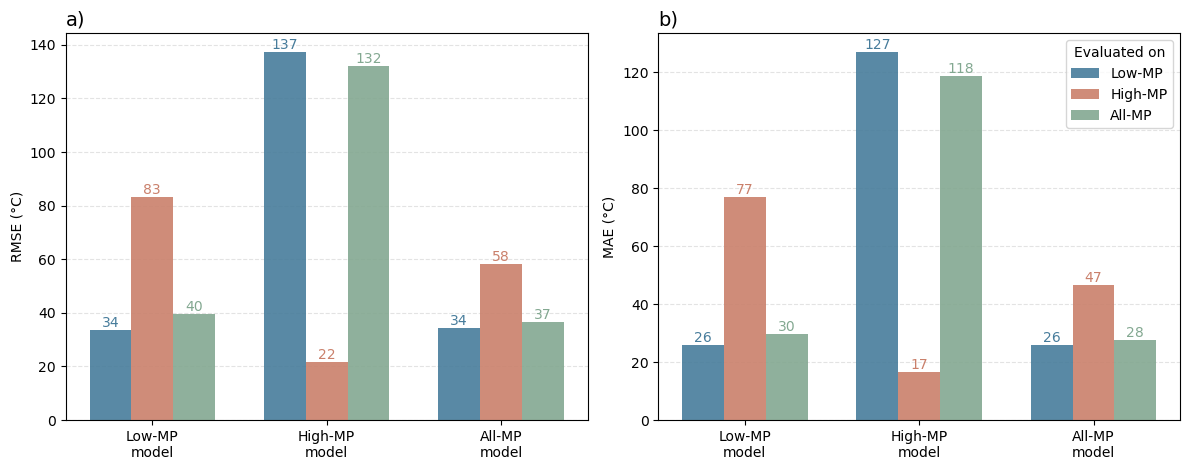

In [6]:
fig = plot_metric_bars('full')
# fig.savefig(OUTPUT_ROOT / 'full' / 'test_metrics_by_model.png', dpi=300, bbox_inches='tight')
plt.show()

## Full run: RMSE by measured MP

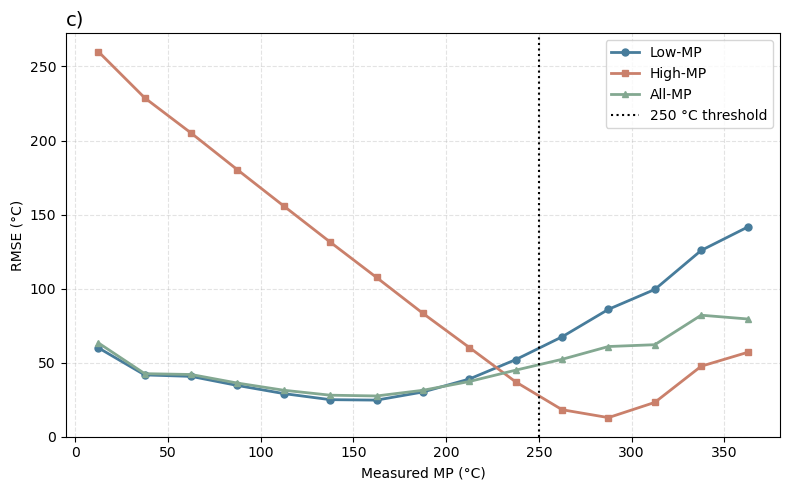

,,L,H,All,N_compounds
MP_bin,MP_bin_center,,,,
"[0.0, 25.0)",12.5,60.0,260.0,63.4,277
"[25.0, 50.0)",37.5,41.7,228.8,42.6,1443
"[50.0, 75.0)",62.5,40.7,205.1,42.0,4227
"[75.0, 100.0)",87.5,34.6,180.2,36.2,6308
"[100.0, 125.0)",112.5,29.1,155.7,31.4,7630
"[125.0, 150.0)",137.5,25.0,131.4,28.0,8396
"[150.0, 175.0)",162.5,24.7,107.5,27.5,7819
"[175.0, 200.0)",187.5,30.2,83.3,31.4,6565
"[200.0, 225.0)",212.5,39.0,60.2,37.3,5087


In [7]:
fig, rmse_by_mp_full = plot_rmse_by_mp('full')
# fig.savefig(OUTPUT_ROOT / 'full' / 'rmse_vs_mp.png', dpi=300, bbox_inches='tight')
plt.show()
display(rmse_by_mp_full)

## Balanced run: test-set performance by model

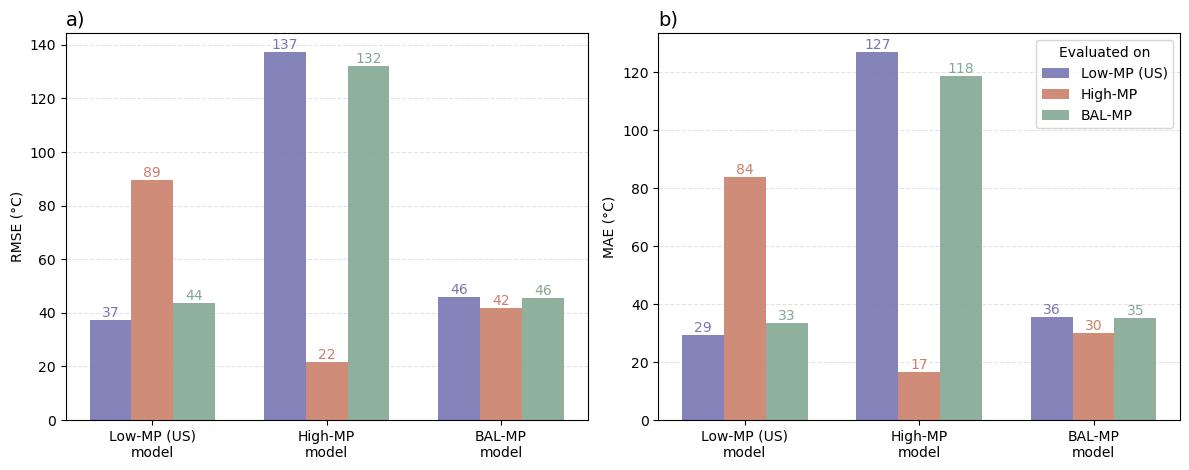

In [8]:
fig = plot_metric_bars('balanced')
# fig.savefig(OUTPUT_ROOT / 'balanced' / 'test_metrics_by_model.png', dpi=300, bbox_inches='tight')
plt.show()

## Balanced run: RMSE by measured MP

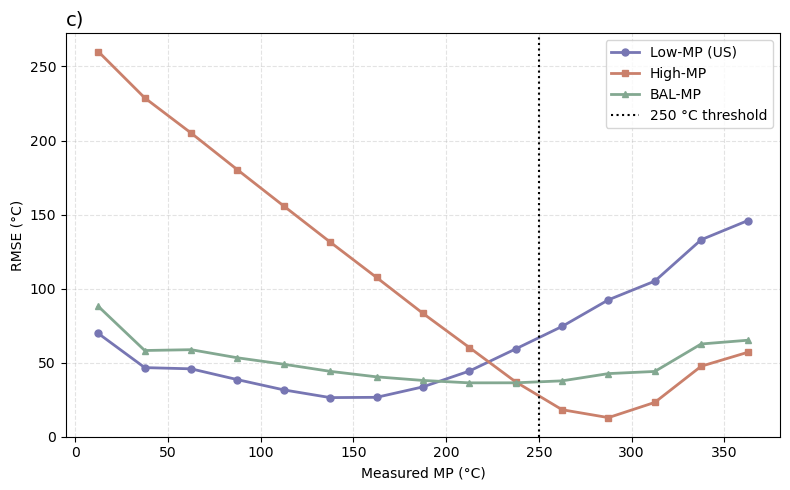

,,L,H,All,N_compounds
MP_bin,MP_bin_center,,,,
"[0.0, 25.0)",12.5,69.7,260.0,88.0,277
"[25.0, 50.0)",37.5,46.7,228.8,58.2,1443
"[50.0, 75.0)",62.5,45.8,205.1,58.8,4227
"[75.0, 100.0)",87.5,38.5,180.2,53.3,6308
"[100.0, 125.0)",112.5,31.6,155.7,48.9,7630
"[125.0, 150.0)",137.5,26.4,131.4,44.1,8396
"[150.0, 175.0)",162.5,26.6,107.5,40.4,7819
"[175.0, 200.0)",187.5,33.7,83.3,38.0,6565
"[200.0, 225.0)",212.5,44.3,60.2,36.4,5087


In [9]:
fig, rmse_by_mp_balanced = plot_rmse_by_mp('balanced')
# fig.savefig(OUTPUT_ROOT / 'balanced' / 'rmse_vs_mp.png', dpi=300, bbox_inches='tight')
plt.show()
display(rmse_by_mp_balanced)